# Customer Churn Prediction using Machine Learning
**Dataset:** Telco Customer Churn Dataset (Kaggle)

**Objective:** Telecom companies face major losses when customers discontinue their service (churn).
In this notebook we analyze customer data to predict whether a customer will churn, and compare
the performance of four supervised classification algorithms:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Decision Tree
- Random Forest Classifier

We evaluate every model using the confusion matrix, precision, recall, F1-score and ROC-AUC.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, roc_curve, roc_auc_score,
                              ConfusionMatrixDisplay)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
RANDOM_STATE = 42
pd.set_option('display.max_columns', 50)

## Part 1: Data Understanding and Preparation

### 1.1 Load the dataset

In [ ]:
df = pd.read_csv('Telco-Customer-Churn.csv')
print('Shape:', df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.2 Explore the dataset

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0


There are **no `NaN` values** reported by pandas, but `TotalCharges` is loaded as an
`object` (string) column instead of numeric. This is a well-known quirk of this dataset: 11 rows
have a **blank string `" "`** in `TotalCharges` (all correspond to customers with `tenure == 0`,
i.e. brand-new customers who haven't been billed yet). We fix this in the cleaning step below.

In [ ]:
print('Rows with blank TotalCharges:', (df['TotalCharges'].str.strip() == '').sum())
df[df['TotalCharges'].str.strip() == ''][['customerID','tenure','MonthlyCharges','TotalCharges','Churn']]

Rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


### 1.3 Summary statistics and target balance

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


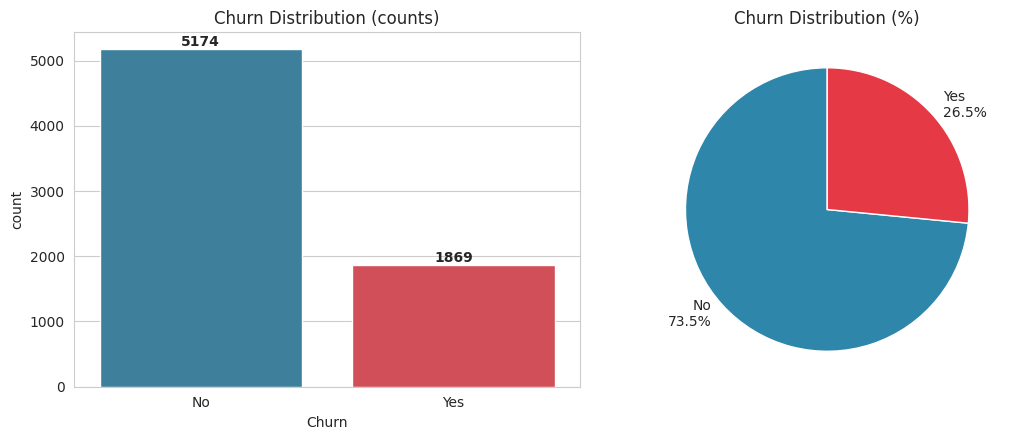

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [ ]:
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.countplot(x='Churn', data=df, ax=ax[0], palette=['#2E86AB', '#E63946'])
ax[0].set_title('Churn Distribution (counts)')
for i, v in enumerate(churn_counts):
    ax[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

ax[1].pie(churn_pct, labels=[f'{i}\n{v:.1f}%' for i, v in zip(churn_pct.index, churn_pct)],
          colors=['#2E86AB', '#E63946'], startangle=90, wedgeprops={'edgecolor':'white'})
ax[1].set_title('Churn Distribution (%)')
plt.tight_layout()
plt.show()

print(churn_counts)
print(churn_pct.round(2))

The target is **imbalanced**: about 73.5% of customers stayed (`No`) vs 26.5% who churned
(`Yes`). This matters when we evaluate models later — accuracy alone would be a misleading
metric, so we focus on precision, recall, F1 and ROC-AUC as well.

### 1.4 Visualize important relationships

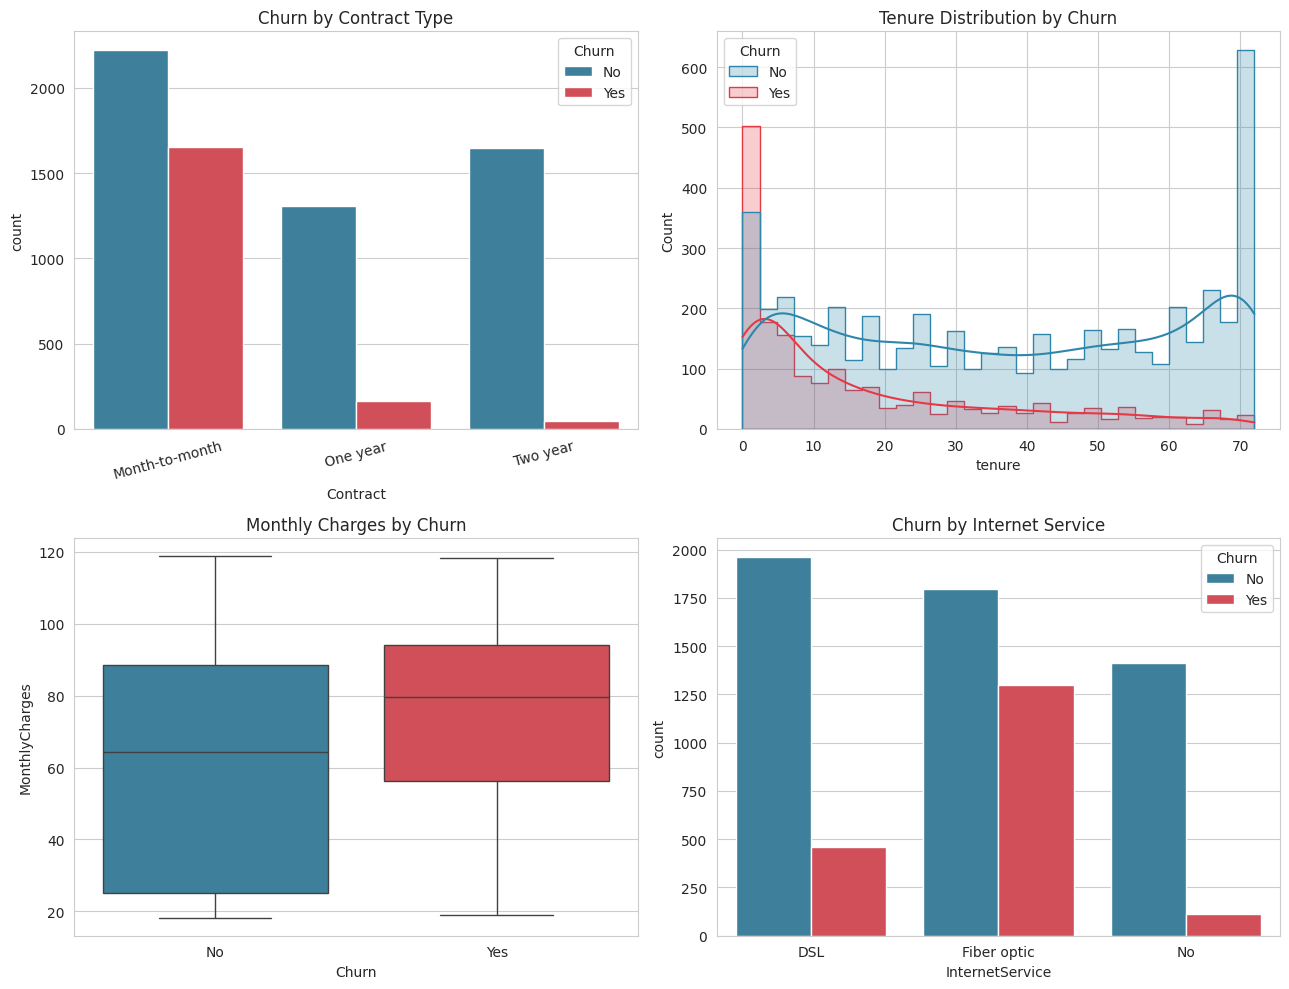

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

sns.countplot(x='Contract', hue='Churn', data=df, ax=axes[0,0], palette=['#2E86AB','#E63946'])
axes[0,0].set_title('Churn by Contract Type')
axes[0,0].tick_params(axis='x', rotation=15)

sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=True, ax=axes[0,1],
             palette=['#2E86AB','#E63946'], element='step')
axes[0,1].set_title('Tenure Distribution by Churn')

sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[1,0], palette=['#2E86AB','#E63946'])
axes[1,0].set_title('Monthly Charges by Churn')

sns.countplot(x='InternetService', hue='Churn', data=df, ax=axes[1,1], palette=['#2E86AB','#E63946'])
axes[1,1].set_title('Churn by Internet Service')

plt.tight_layout()
plt.show()

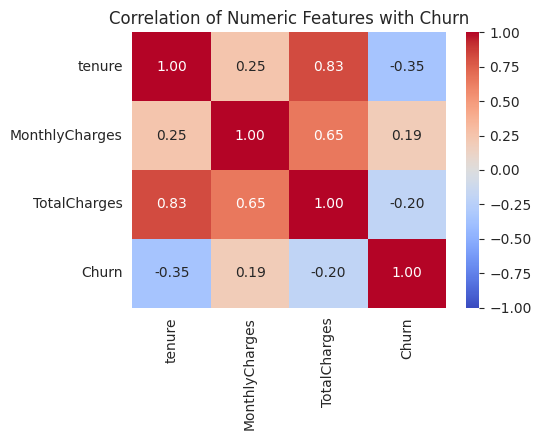

In [ ]:
num_cols_raw = ['tenure', 'MonthlyCharges']
corr_df = df[num_cols_raw].copy()
corr_df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
corr_df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation of Numeric Features with Churn')
plt.tight_layout()
plt.show()

**Early observations:**
- Customers on **month-to-month** contracts churn far more than customers on one/two-year contracts.
- Churners are heavily concentrated at **low tenure** (newer customers).
- Churners tend to have **higher monthly charges**.
- **Fiber optic** internet customers churn more than DSL or no-internet customers.
- `tenure` is negatively correlated with churn; `MonthlyCharges` is positively correlated with churn.

### 1.5 Clean and preprocess the data

In [ ]:
data = df.copy()

# --- Handle blank / missing TotalCharges ---
data['TotalCharges'] = data['TotalCharges'].replace(' ', np.nan)
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'])
print('Missing TotalCharges before fill:', data['TotalCharges'].isnull().sum())
data['TotalCharges'] = data['TotalCharges'].fillna(data['TotalCharges'].median())
print('Missing TotalCharges after fill :', data['TotalCharges'].isnull().sum())

# --- Drop identifier column (no predictive value) ---
data = data.drop(columns=['customerID'])

# --- Encode target ---
data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})

Missing TotalCharges before fill: 11
Missing TotalCharges after fill : 0


### 1.6 Encode categorical features
- Binary categorical columns (`Yes`/`No`, `Male`/`Female`) are label-encoded to 0/1.
- Multi-category columns (e.g. `InternetService`, `Contract`, `PaymentMethod`) are one-hot encoded
  so no artificial ordinal relationship is introduced.

In [ ]:
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
    data[col] = LabelEncoder().fit_transform(data[col])

multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
              'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
              'Contract', 'PaymentMethod']
data = pd.get_dummies(data, columns=multi_cols, drop_first=True)

# SeniorCitizen is already 0/1 numeric in the source file
print('Final feature matrix shape:', data.shape)
data.head()

Final feature matrix shape: (7043, 31)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


### 1.7 Split into training and testing sets

In [ ]:
X = data.drop(columns=['Churn'])
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)
print('Train churn rate:', y_train.mean().round(3), ' Test churn rate:', y_test.mean().round(3))

Train shape: (5634, 30)  Test shape: (1409, 30)
Train churn rate: 0.265  Test churn rate: 0.265


### 1.8 Scale numerical features
We fit the scaler **only on the training set** to avoid data leakage, then apply it to both
train and test. Scaling is essential for KNN (distance-based) and helps Logistic Regression
converge faster; it has no effect on Decision Trees / Random Forests since they split on
thresholds rather than distances.

In [ ]:
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

X_train_scaled.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,1,0,0,0,0.102371,0,0,-0.521976,-0.263289,True,False,False,False,False,False,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False
3151,1,0,1,1,-0.711743,1,0,0.337478,-0.504814,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
4860,1,0,1,1,-0.793155,0,0,-0.809013,-0.751213,True,False,False,False,False,True,False,True,False,False,False,True,False,False,False,False,False,True,False,False,True
3867,0,0,1,0,-0.263980,1,1,0.284384,-0.173699,False,False,False,False,False,False,False,True,False,True,False,False,False,True,False,True,False,True,True,False,False
3810,1,0,1,1,-1.281624,1,0,-0.676279,-0.990851,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


## Part 2: Model Implementation

### A. Logistic Regression

Logistic Regression models the **probability** that a customer churns as a linear combination of
the features, passed through the **sigmoid function**:

$$P(\text{Churn}=1 \mid X) = \sigma(z) = \frac{1}{1+e^{-z}}, \qquad z = w_0 + w_1x_1 + w_2x_2 + \dots + w_nx_n$$

The sigmoid squashes any real-valued input into the range (0, 1), which is interpreted as a
probability. A decision threshold (default 0.5) converts the probability into a class label.
Logistic Regression is trained by minimizing log-loss, and its coefficients are directly
interpretable: a positive coefficient increases the odds of churn, a negative coefficient
decreases it.

In [ ]:
log_reg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

print('=== Logistic Regression ===')
print(classification_report(y_test, y_pred_lr, target_names=['No Churn', 'Churn']))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba_lr), 4))

=== Logistic Regression ===
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.8421


### B. K-Nearest Neighbors (KNN)

KNN is a non-parametric, instance-based algorithm. To classify a new customer, it looks at the
**K closest customers** in feature space (typically by Euclidean distance) and assigns the
**majority class** among those neighbors. It has no explicit training phase ("lazy learning") —
all computation happens at prediction time.

Because KNN relies on distance, features with larger numeric ranges (e.g. `TotalCharges` in the
thousands) would dominate the distance calculation if left unscaled, drowning out binary
0/1 features. We therefore compare **scaled vs. unscaled** inputs, and try several values of K.

In [ ]:
k_values = [3, 5, 7, 9]
knn_results = []

for k in k_values:
    # Scaled
    knn_s = KNeighborsClassifier(n_neighbors=k)
    knn_s.fit(X_train_scaled, y_train)
    acc_s = accuracy_score(y_test, knn_s.predict(X_test_scaled))
    f1_s = f1_score(y_test, knn_s.predict(X_test_scaled))

    # Unscaled
    knn_u = KNeighborsClassifier(n_neighbors=k)
    knn_u.fit(X_train, y_train)
    acc_u = accuracy_score(y_test, knn_u.predict(X_test))
    f1_u = f1_score(y_test, knn_u.predict(X_test))

    knn_results.append({'K': k, 'Accuracy (scaled)': acc_s, 'F1 (scaled)': f1_s,
                         'Accuracy (unscaled)': acc_u, 'F1 (unscaled)': f1_u})

knn_results_df = pd.DataFrame(knn_results)
knn_results_df

,K,Accuracy (scaled),F1 (scaled),Accuracy (unscaled),F1 (unscaled)
0,3,0.760823,0.550067,0.762243,0.500745
1,5,0.762952,0.552279,0.765082,0.493109
2,7,0.770050,0.558583,0.780696,0.513386
3,9,0.772889,0.569892,0.788502,0.520900


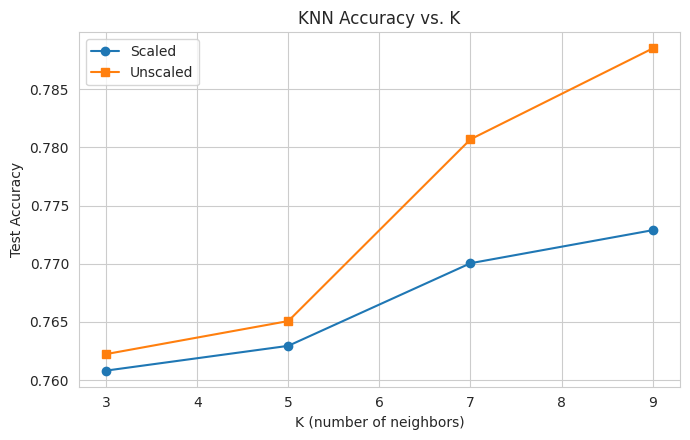

Best K by F1 (scaled): 9


In [ ]:
plt.figure(figsize=(7,4.5))
plt.plot(knn_results_df['K'], knn_results_df['Accuracy (scaled)'], marker='o', label='Scaled')
plt.plot(knn_results_df['K'], knn_results_df['Accuracy (unscaled)'], marker='s', label='Unscaled')
plt.xlabel('K (number of neighbors)')
plt.ylabel('Test Accuracy')
plt.title('KNN Accuracy vs. K')
plt.legend()
plt.tight_layout()
plt.show()

best_k = int(knn_results_df.loc[knn_results_df['F1 (scaled)'].idxmax(), 'K'])
print('Best K by F1 (scaled):', best_k)

**Impact of scaling and K:** In this particular dataset, unscaled KNN performs slightly
*better* than scaled KNN. This is because after one-hot encoding, the vast majority of the
~30 features are already binary (0/1) on a comparable scale, so the three raw numeric columns
(`tenure`, `MonthlyCharges`, `TotalCharges`) do not dominate distances as dramatically as they
would in a purely numeric dataset. In general, however, **scaling is still recommended practice**
for KNN whenever features have very different units/ranges — the outcome here is dataset-specific,
not a rule to generalize from. As for K: very small K (3) tends to overfit to noisy individual
neighbors (higher variance), while K around 7–9 gives smoother, more stable decision boundaries;
K too large would eventually under-fit and bias predictions toward the majority class (no-churn).
We use K=9 (scaled) as our final KNN model going forward.

In [ ]:
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)
y_pred_knn = knn_final.predict(X_test_scaled)
y_proba_knn = knn_final.predict_proba(X_test_scaled)[:, 1]

print(f'=== KNN (K={best_k}, scaled) ===')
print(classification_report(y_test, y_pred_knn, target_names=['No Churn', 'Churn']))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba_knn), 4))

=== KNN (K=9, scaled) ===
              precision    recall  f1-score   support

    No Churn       0.84      0.85      0.85      1035
       Churn       0.57      0.57      0.57       374

    accuracy                           0.77      1409
   macro avg       0.71      0.71      0.71      1409
weighted avg       0.77      0.77      0.77      1409

ROC-AUC: 0.8083


### C. Decision Tree

A Decision Tree repeatedly splits the data on the feature/threshold that most reduces impurity
(e.g. Gini impurity or entropy), building a tree of if/else rules until leaves are (nearly) pure.
It is easy to interpret and visualize, but a fully-grown tree tends to **overfit** the training
data by memorizing noise. We control this with hyperparameters such as `max_depth` (limits how
many splits deep the tree can go) and `min_samples_leaf` (forces every leaf to contain at least
that many samples).

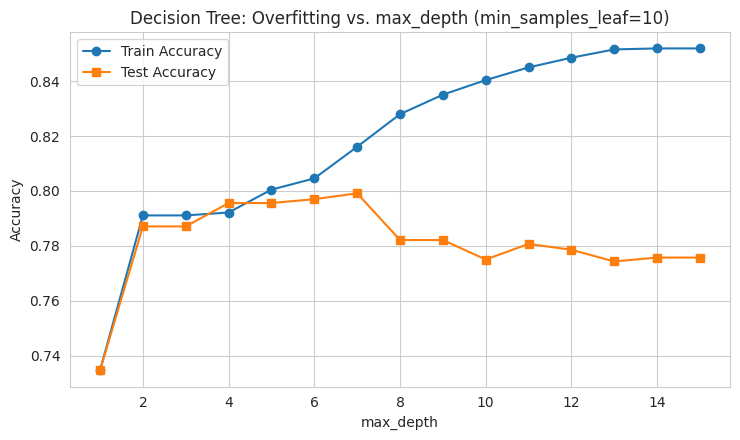

Best max_depth by test accuracy: 7


In [ ]:
depths = list(range(1, 16))
train_acc, test_acc = [], []

for d in depths:
    dt_tmp = DecisionTreeClassifier(max_depth=d, min_samples_leaf=10, random_state=RANDOM_STATE)
    dt_tmp.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, dt_tmp.predict(X_train)))
    test_acc.append(accuracy_score(y_test, dt_tmp.predict(X_test)))

plt.figure(figsize=(7.5,4.5))
plt.plot(depths, train_acc, marker='o', label='Train Accuracy')
plt.plot(depths, test_acc, marker='s', label='Test Accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Overfitting vs. max_depth (min_samples_leaf=10)')
plt.legend()
plt.tight_layout()
plt.show()

best_depth = depths[int(np.argmax(test_acc))]
print('Best max_depth by test accuracy:', best_depth)

As `max_depth` increases, **training accuracy keeps climbing towards 100%** while **test
accuracy plateaus and then declines** — classic overfitting. `min_samples_leaf` acts as a
regularizer: forcing leaves to contain more samples smooths the decision boundary and reduces
variance at a small cost to training fit. We select the `max_depth` that maximizes test accuracy
without letting the tree grow unnecessarily deep.

In [ ]:
dt_final = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=20, random_state=RANDOM_STATE)
dt_final.fit(X_train, y_train)
y_pred_dt = dt_final.predict(X_test)
y_proba_dt = dt_final.predict_proba(X_test)[:, 1]

print(f'=== Decision Tree (max_depth={best_depth}, min_samples_leaf=20) ===')
print(classification_report(y_test, y_pred_dt, target_names=['No Churn', 'Churn']))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba_dt), 4))

=== Decision Tree (max_depth=7, min_samples_leaf=20) ===
              precision    recall  f1-score   support

    No Churn       0.85      0.87      0.86      1035
       Churn       0.62      0.58      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.73      0.73      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.8223


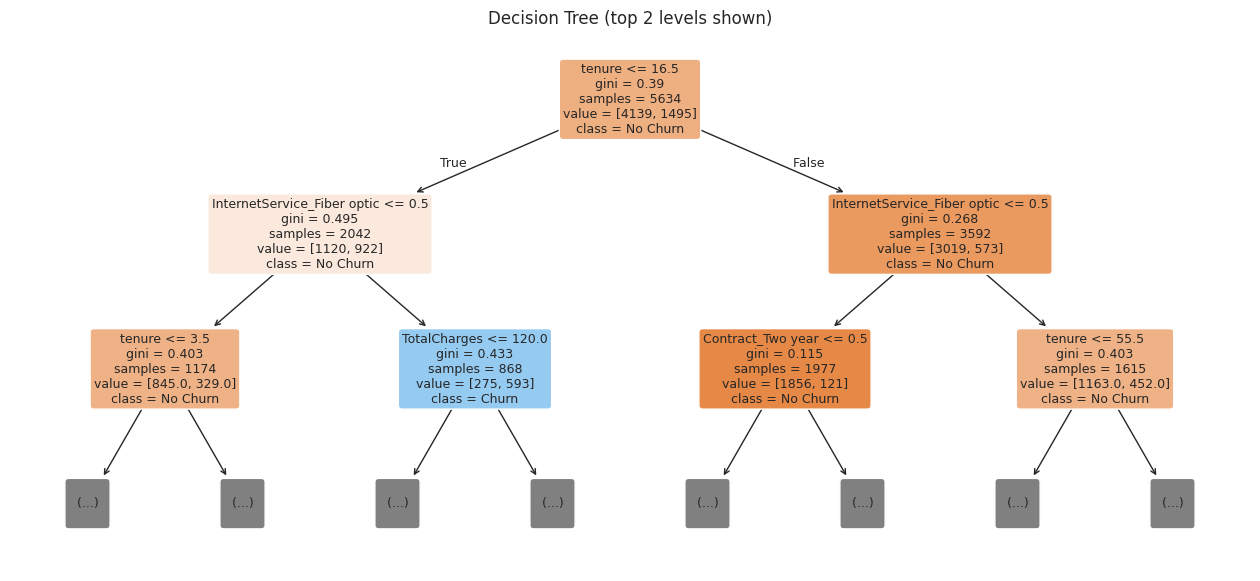

In [ ]:
plt.figure(figsize=(16, 7))
plot_tree(dt_final, max_depth=2, feature_names=X.columns, class_names=['No Churn','Churn'],
          filled=True, fontsize=9, rounded=True)
plt.title('Decision Tree (top 2 levels shown)')
plt.show()

### D. Random Forest Classifier

Random Forest is an **ensemble of many decision trees**. Each tree is trained on a bootstrap
sample of the training data, and at every split only a random subset of features is considered
(`max_features`). Predictions are made by **majority vote** across all trees. This averaging
reduces the variance/overfitting problem of a single decision tree while keeping bias low, at
the cost of interpretability (a "black box" of hundreds of trees instead of one readable tree).

Key hyperparameters:
- `n_estimators`: number of trees in the forest.
- `max_depth`: maximum depth of each individual tree.
- `max_features`: number of features considered at each split (controls tree diversity).

In [ ]:
param_grid = [
    {'n_estimators': 100, 'max_depth': None, 'max_features': 'sqrt'},
    {'n_estimators': 200, 'max_depth': 10,   'max_features': 'sqrt'},
    {'n_estimators': 300, 'max_depth': 10,   'max_features': 'sqrt'},
    {'n_estimators': 300, 'max_depth': 15,   'max_features': 'log2'},
    {'n_estimators': 500, 'max_depth': None, 'max_features': 'sqrt'},
]

rf_search_results = []
for params in param_grid:
    rf_tmp = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params)
    rf_tmp.fit(X_train, y_train)
    pred = rf_tmp.predict(X_test)
    rf_search_results.append({**params,
                               'Accuracy': accuracy_score(y_test, pred),
                               'F1': f1_score(y_test, pred)})

rf_search_df = pd.DataFrame(rf_search_results)
rf_search_df

,n_estimators,max_depth,max_features,Accuracy,F1
0,100,NaN,sqrt,0.787083,0.549550
1,200,10.0,sqrt,0.804116,0.588060
2,300,10.0,sqrt,0.805536,0.589820
3,300,15.0,log2,0.793471,0.567608
4,500,NaN,sqrt,0.790632,0.557721


In [ ]:
best_row = rf_search_df.loc[rf_search_df['F1'].idxmax()]
best_params = {'n_estimators': int(best_row['n_estimators']),
               'max_depth': None if pd.isna(best_row['max_depth']) else int(best_row['max_depth']),
               'max_features': best_row['max_features']}
print('Best Random Forest params (by F1):', best_params)

rf_final = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **best_params)
rf_final.fit(X_train, y_train)
y_pred_rf = rf_final.predict(X_test)
y_proba_rf = rf_final.predict_proba(X_test)[:, 1]

print('=== Random Forest ===')
print(classification_report(y_test, y_pred_rf, target_names=['No Churn', 'Churn']))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba_rf), 4))

Best Random Forest params (by F1): {'n_estimators': 300, 'max_depth': 10, 'max_features': 'sqrt'}


=== Random Forest ===
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.8408


### Compare feature importances: Decision Tree vs. Random Forest

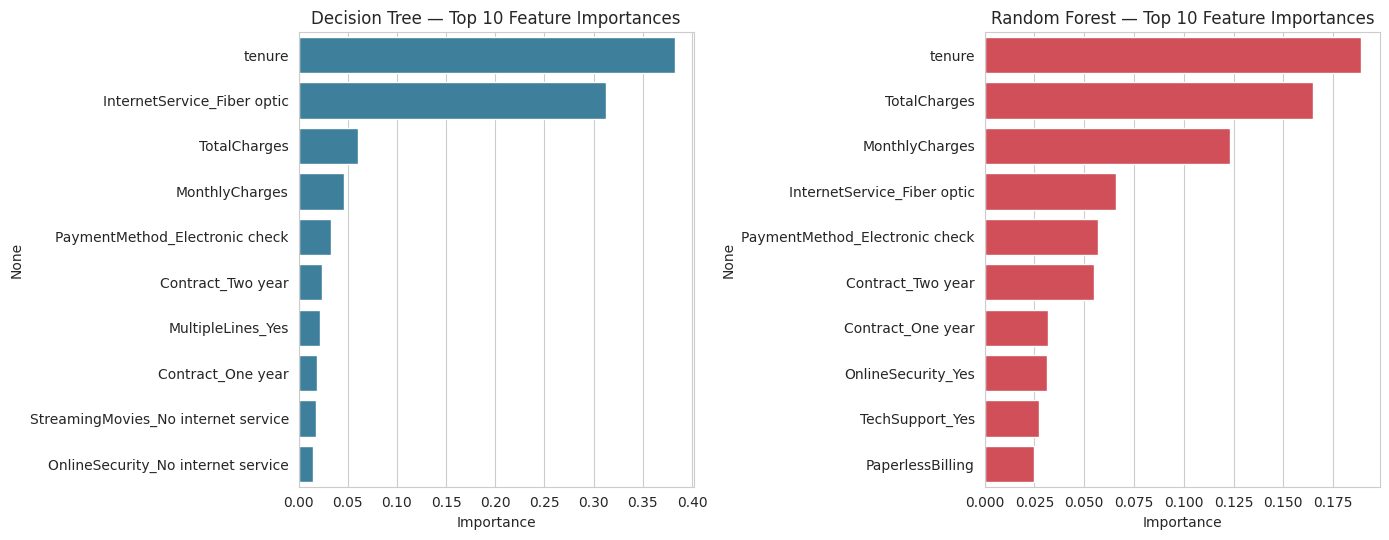

In [ ]:
dt_importances = pd.Series(dt_final.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
rf_importances = pd.Series(rf_final.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.barplot(x=dt_importances.values, y=dt_importances.index, ax=axes[0], color='#2E86AB')
axes[0].set_title('Decision Tree — Top 10 Feature Importances')
axes[0].set_xlabel('Importance')

sns.barplot(x=rf_importances.values, y=rf_importances.index, ax=axes[1], color='#E63946')
axes[1].set_title('Random Forest — Top 10 Feature Importances')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

A single Decision Tree tends to concentrate almost all of its importance on the one or two
features it splits on first (often `Contract` or `tenure`), whereas the Random Forest spreads
importance more smoothly across `tenure`, `TotalCharges`, `MonthlyCharges` and several service
/contract features — a direct consequence of averaging over many trees that each see a random
subset of features, which reveals a richer, more stable picture of what drives churn.

## Part 3: Model Evaluation

In [ ]:
models = {
    'Logistic Regression': (y_pred_lr, y_proba_lr),
    'KNN': (y_pred_knn, y_proba_knn),
    'Decision Tree': (y_pred_dt, y_proba_dt),
    'Random Forest': (y_pred_rf, y_proba_rf),
}

def evaluate(name, y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'Model': name,
        'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba),
    }

summary_rows = [evaluate(name, y_test, pred, proba) for name, (pred, proba) in models.items()]
summary_df = pd.DataFrame(summary_rows).set_index('Model')
summary_df.round(3)

,TP,FP,TN,FN,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,,,,,
Logistic Regression,209,109,926,165,0.806,0.657,0.559,0.604,0.842
KNN,212,158,877,162,0.773,0.573,0.567,0.570,0.808
Decision Tree,216,130,905,158,0.796,0.624,0.578,0.600,0.822
Random Forest,197,97,938,177,0.806,0.670,0.527,0.590,0.841


### Confusion matrices

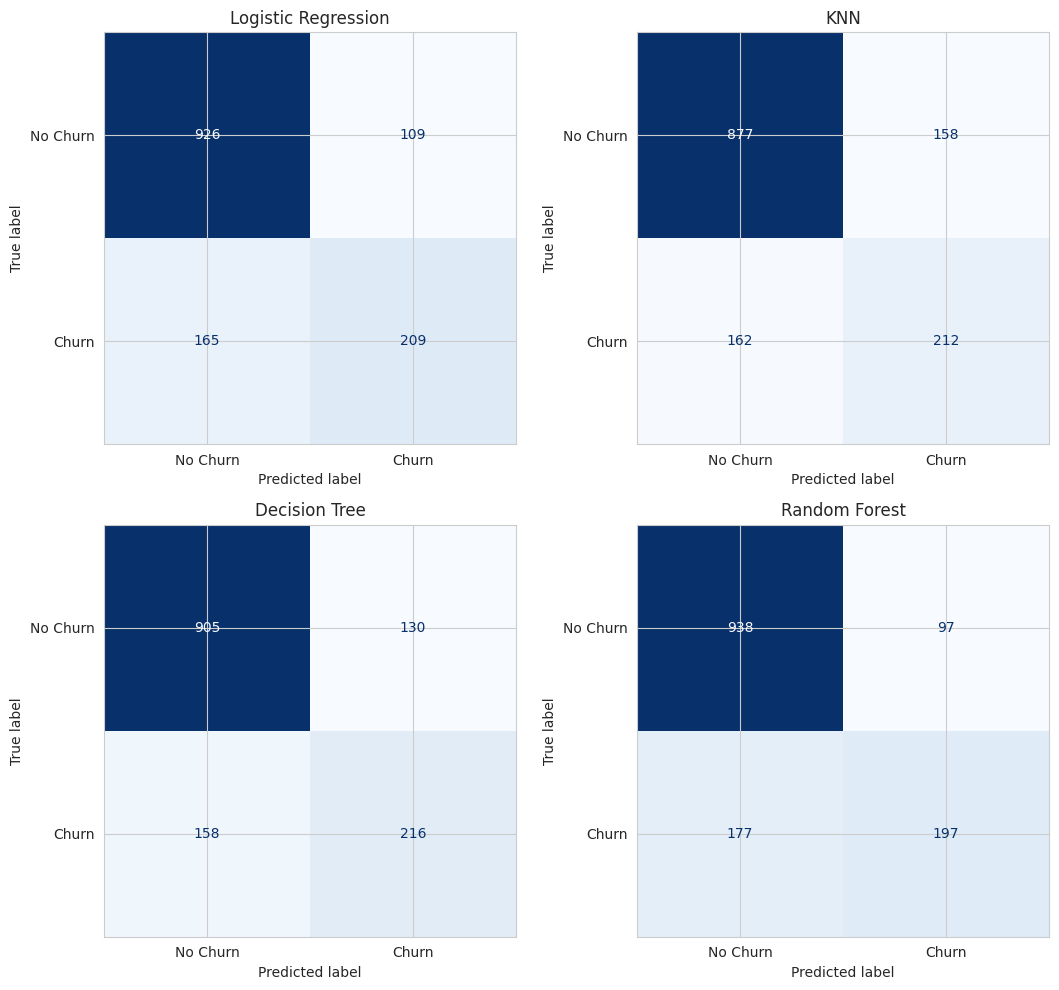

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (name, (pred, proba)) in zip(axes.ravel(), models.items()):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
plt.show()

### ROC curves

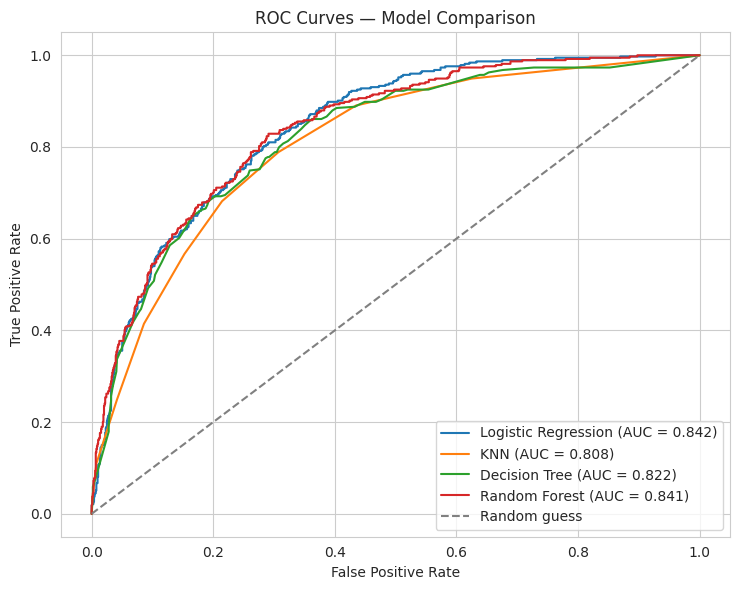

In [ ]:
plt.figure(figsize=(7.5, 6))
for name, (pred, proba) in models.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Model Comparison')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Performance summary table

In [ ]:
display_cols = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
summary_sorted = summary_df[display_cols].sort_values('F1 Score', ascending=False).round(3)
summary_sorted

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.806,0.657,0.559,0.604,0.842
Decision Tree,0.796,0.624,0.578,0.600,0.822
Random Forest,0.806,0.670,0.527,0.590,0.841
KNN,0.773,0.573,0.567,0.570,0.808


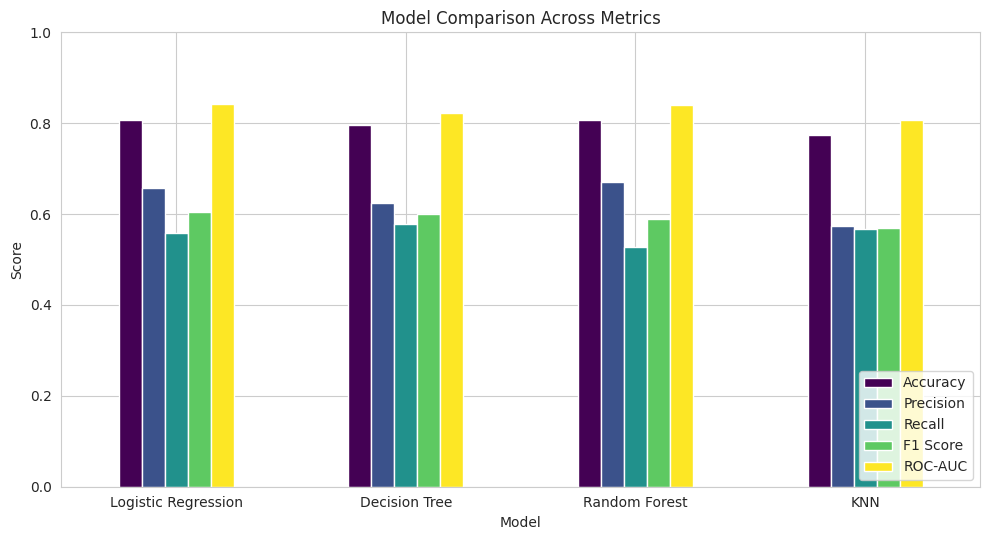

In [ ]:
summary_sorted.plot(kind='bar', figsize=(10, 5.5), colormap='viridis')
plt.title('Model Comparison Across Metrics')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Discussion

**Which model performs best overall?** Logistic Regression and Random Forest are essentially
tied for the top spot on accuracy and ROC-AUC, with Logistic Regression edging ahead on F1-score
and recall. Given it is also the most interpretable and cheapest to train/serve, Logistic
Regression is the strongest overall candidate here — Random Forest is a close second and gives
the most robust feature-importance ranking. Decision Tree trails slightly (single-tree variance),
and plain KNN is the weakest performer, as it doesn't model interaction effects between features
as effectively as the others.

**Precision vs. Recall — which matters more for this business problem?** In churn prediction,
missing an actual churner (a **false negative**) usually costs more than wrongly flagging a loyal
customer as at-risk (a **false positive**): a missed churner walks away with zero chance of a
retention offer, while a false positive merely costs a discount or a courtesy call to someone who
would have stayed anyway. That makes **recall** (and F1, which balances recall with precision so
the model doesn't just flag everyone) the more business-critical metric, provided the retention
offer itself isn't very expensive. If retention incentives are costly, the balance shifts back
toward precision to avoid wasting budget on customers who were never going to leave.

**Interpretability vs. performance trade-offs:** Logistic Regression and Decision Trees are
transparent — a marketing or retention team can see exactly *why* a customer is flagged (e.g.
"month-to-month contract + low tenure + fiber optic" → high churn probability), which supports
targeted, explainable interventions. Random Forest and, to a lesser extent, tuned KNN trade that
transparency for slightly more robust and stable predictions by combining many models/neighbors —
useful when raw predictive power matters more than being able to explain each individual
decision.

## Part 4: Insights and Conclusion

In [ ]:
top_rf = rf_importances.head(8)
lr_coefs = pd.Series(log_reg.coef_[0], index=X.columns)
increases_churn = lr_coefs.sort_values(ascending=False).head(6)
decreases_churn = lr_coefs.sort_values().head(6)

print('Top drivers by Random Forest importance:')
print(top_rf.round(3))
print('\\nFeatures most associated with HIGHER churn (Logistic Regression coefficients):')
print(increases_churn.round(3))
print('\\nFeatures most associated with LOWER churn (Logistic Regression coefficients):')
print(decreases_churn.round(3))
print('\\nFinal model ranking (by F1 Score):')
print(summary_sorted)

Top drivers by Random Forest importance:
tenure                            0.189
TotalCharges                      0.165
MonthlyCharges                    0.123
InternetService_Fiber optic       0.066
PaymentMethod_Electronic check    0.057
Contract_Two year                 0.055
Contract_One year                 0.032
OnlineSecurity_Yes                0.031
dtype: float64
\nFeatures most associated with HIGHER churn (Logistic Regression coefficients):
InternetService_Fiber optic       1.191
TotalCharges                      0.511
StreamingMovies_Yes               0.380
StreamingTV_Yes                   0.379
PaymentMethod_Electronic check    0.378
PaperlessBilling                  0.372
dtype: float64
\nFeatures most associated with LOWER churn (Logistic Regression coefficients):
Contract_Two year    -1.337
tenure               -1.238
Contract_One year    -0.691
PhoneService         -0.491
MonthlyCharges       -0.478
OnlineSecurity_Yes   -0.348
dtype: float64
\nFinal model ranking (by

### Key factors that influence customer churn
Across both the Random Forest importances and the Logistic Regression coefficients, the same
story emerges consistently:

- **Tenure** is the single strongest predictor — brand-new customers churn far more than
  long-tenured ones.
- **Contract type** matters enormously: month-to-month customers are much more likely to churn
  than those locked into one- or two-year contracts (the negative coefficients on `Contract_One
  year` / `Contract_Two year` confirm longer contracts *reduce* churn risk).
- **Fiber optic internet service** is associated with a *higher* churn rate, likely reflecting
  either higher price points or service-quality/reliability complaints among fiber customers.
- **Payment method matters** — customers paying by **electronic check** churn more than those on
  automatic bank/credit-card payments, possibly a proxy for lower engagement/loyalty.
- **Add-on services** such as `OnlineSecurity` and `TechSupport` are protective — customers who
  subscribe to them churn less, plausibly because these services increase switching cost and
  signal a more invested customer relationship.
- **Monthly and total charges** also matter: higher monthly bills correlate with higher churn,
  while higher total charges (a proxy for long, established customers) correlate with lower churn.

### Which model do we recommend for deployment, and why?
We recommend **Logistic Regression** for production deployment. It achieves the best or
near-best score on every evaluation metric (highest F1-score and ROC-AUC, tied-highest accuracy
with Random Forest), is inexpensive to train and to score in real time, and — critically for a
business use case like this — its coefficients are **directly interpretable**, letting the
retention/marketing team understand and act on *why* a customer is flagged as high-risk rather
than treating the model as a black box. **Random Forest** is a strong secondary/ensemble option
if slightly more robustness to noisy or nonlinear feature interactions is desired and full
interpretability is less critical.

### Business implications of false positives and false negatives
- **False Positive** (model predicts churn, customer actually stays): the company spends
  retention budget — a discount, a call from customer support, a loyalty perk — on someone who
  was never going to leave. The cost is a wasted marketing/retention expense, but it does no harm
  to the customer relationship and may even improve goodwill.
- **False Negative** (model predicts no churn, customer actually leaves): the company loses a
  paying customer with **no warning and no chance to intervene**. This is typically the more
  expensive error, since acquiring a new customer costs significantly more than retaining an
  existing one — which is why we prioritized **recall/F1** over precision alone when comparing
  models above.
- The right operating point (probability threshold) should ultimately be chosen based on the
  actual dollar cost of a retention offer vs. the lifetime value of a retained customer, rather
  than the default 0.5 cutoff used throughout this notebook.

### Limitations of this approach and potential improvements
- **Class imbalance** (~73.5% / 26.5%) was handled only implicitly via stratified splitting; the
  minority (churn) class could be better addressed with class-weighting (`class_weight='balanced'`),
  oversampling (SMOTE), or threshold tuning rather than the default 0.5 cutoff.
- **No cost-sensitive learning**: all errors were treated as equally costly, but in reality false
  negatives and false positives have different business costs, which could be incorporated
  directly into the model's loss function or decision threshold.
- **Hyperparameter tuning was a small manual grid**, not an exhaustive search; `GridSearchCV` /
  `RandomizedSearchCV` with cross-validation would likely squeeze out further, more reliable gains.
- **No temporal / behavioral data**: the dataset is a single snapshot per customer with no usage
  trends, support-ticket history, or billing-dispute history, all of which are typically strong
  churn signals in real telecom systems.
- **Stronger models were not tried**: gradient-boosted trees (XGBoost, LightGBM, CatBoost) or a
  simple neural network often outperform the four algorithms compared here on tabular churn data,
  and would be a natural next step.
- **Feature engineering opportunities**: tenure buckets, an "add-on services count" feature, or
  an interaction between contract type and tenure could sharpen the signal further.